In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Importing the CSV dataset

data = pd.read_csv(
    "/content/SmartPantry_Dataset.csv"
)

print("Dataset imported successfully!")

display(data.head(10))

Dataset imported successfully!


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity,Waste_Risk
0,Milk,Refrigerator,7,65,7.0,68,Medium
1,Cooked Food,Room Temperature,9,64,29.7,36,High
2,Meat,Freezer,3,30,-13.0,86,Low
3,Fruits,Room Temperature,9,82,27.4,41,High
4,Fruits,Freezer,13,72,-10.8,95,High
5,Leafy Vegetables,Room Temperature,2,78,29.0,51,Medium
6,Milk,Freezer,5,52,-13.4,58,Low
7,Meat,Refrigerator,10,91,2.7,44,High
8,Bread,Room Temperature,9,45,25.4,85,Medium
9,Milk,Refrigerator,10,83,6.5,79,High


In [3]:
# Understanding the dataset

print("Dataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nFirst 5 Records:")
display(data.head())

print("\nLast 5 Records:")
display(data.tail())

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe(include="all"))

Dataset Shape:
(1200, 7)

Column Names:
['Food_Type', 'Storage_Type', 'Days_Stored', 'Quantity_Remaining', 'Temperature', 'Humidity', 'Waste_Risk']

First 5 Records:


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity,Waste_Risk
0,Milk,Refrigerator,7,65,7.0,68,Medium
1,Cooked Food,Room Temperature,9,64,29.7,36,High
2,Meat,Freezer,3,30,-13.0,86,Low
3,Fruits,Room Temperature,9,82,27.4,41,High
4,Fruits,Freezer,13,72,-10.8,95,High



Last 5 Records:


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity,Waste_Risk
1195,Meat,Refrigerator,3,29,5.1,88,Low
1196,Meat,Room Temperature,8,87,23.7,50,High
1197,Leafy Vegetables,Refrigerator,2,99,7.3,77,Low
1198,Cooked Food,Room Temperature,6,78,28.3,82,High
1199,Meat,Room Temperature,8,18,20.5,77,High



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Food_Type           1200 non-null   object 
 1   Storage_Type        1200 non-null   object 
 2   Days_Stored         1200 non-null   int64  
 3   Quantity_Remaining  1200 non-null   int64  
 4   Temperature         1200 non-null   float64
 5   Humidity            1200 non-null   int64  
 6   Waste_Risk          1200 non-null   object 
dtypes: float64(1), int64(3), object(3)
memory usage: 65.8+ KB

Statistical Summary:


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity,Waste_Risk
count,1200,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200
unique,7,3,NaN,NaN,NaN,NaN,3
top,Cooked Food,Refrigerator,NaN,NaN,NaN,NaN,Medium
freq,201,609,NaN,NaN,NaN,NaN,439
mean,NaN,NaN,7.303333,55.566667,7.302833,64.761667,NaN
std,NaN,NaN,4.039792,25.941370,13.529701,17.512056,NaN
min,NaN,NaN,1.000000,10.000000,-18.000000,35.000000,NaN
25%,NaN,NaN,4.000000,33.000000,2.400000,50.000000,NaN
50%,NaN,NaN,7.000000,57.000000,5.400000,65.000000,NaN
75%,NaN,NaN,11.000000,78.000000,21.500000,80.000000,NaN


In [4]:
# Checking missing values

print("Missing Values in Each Column:")
print(data.isnull().sum())

# Checking duplicate records

print("\nNumber of Duplicate Rows:")
print(data.duplicated().sum())

Missing Values in Each Column:
Food_Type             0
Storage_Type          0
Days_Stored           0
Quantity_Remaining    0
Temperature           0
Humidity              0
Waste_Risk            0
dtype: int64

Number of Duplicate Rows:
0


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Cleaning the dataset

# Removing duplicate records

data = data.drop_duplicates()

# Removing extra spaces from text columns

categorical_columns = [
    "Food_Type",
    "Storage_Type",
    "Waste_Risk"
]

for column in categorical_columns:
    data[column] = data[column].astype(str).str.strip()

# Converting numerical columns to numeric format

numerical_columns = [
    "Days_Stored",
    "Quantity_Remaining",
    "Temperature",
    "Humidity"
]

for column in numerical_columns:
    data[column] = pd.to_numeric(
        data[column],
        errors="coerce"
    )

# Removing rows with missing values

data = data.dropna()

print("Data cleaning completed!")

print("Final Dataset Shape:", data.shape)

display(data.head())

Data cleaning completed!
Final Dataset Shape: (1200, 7)


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity,Waste_Risk
0,Milk,Refrigerator,7,65,7.0,68,Medium
1,Cooked Food,Room Temperature,9,64,29.7,36,High
2,Meat,Freezer,3,30,-13.0,86,Low
3,Fruits,Room Temperature,9,82,27.4,41,High
4,Fruits,Freezer,13,72,-10.8,95,High


In [7]:
# Checking target variable

print("Waste Risk Categories:")

print(data["Waste_Risk"].unique())

print("\nCategory Distribution:")

print(data["Waste_Risk"].value_counts())

Waste Risk Categories:
['Medium' 'High' 'Low']

Category Distribution:
Waste_Risk
Medium    439
High      434
Low       327
Name: count, dtype: int64


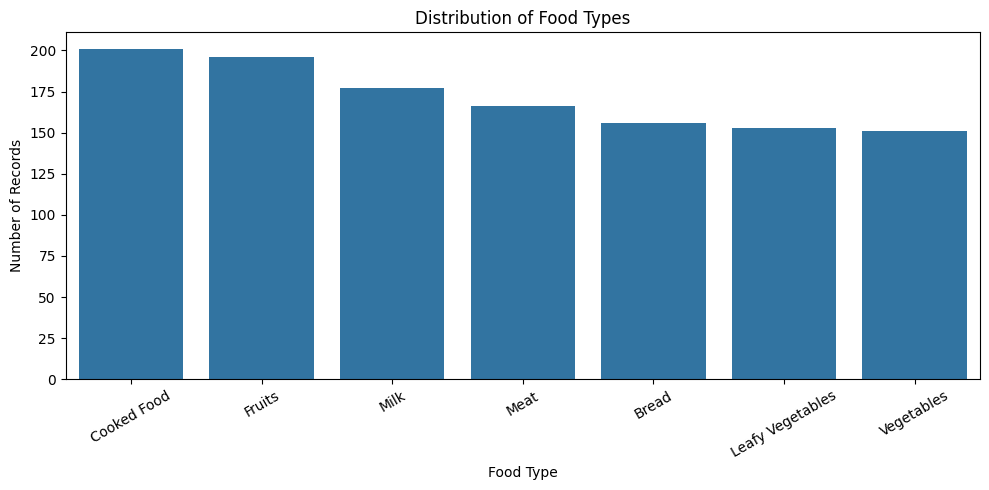

In [8]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Food_Type",
    order=data["Food_Type"].value_counts().index
)

plt.title("Distribution of Food Types")
plt.xlabel("Food Type")
plt.ylabel("Number of Records")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

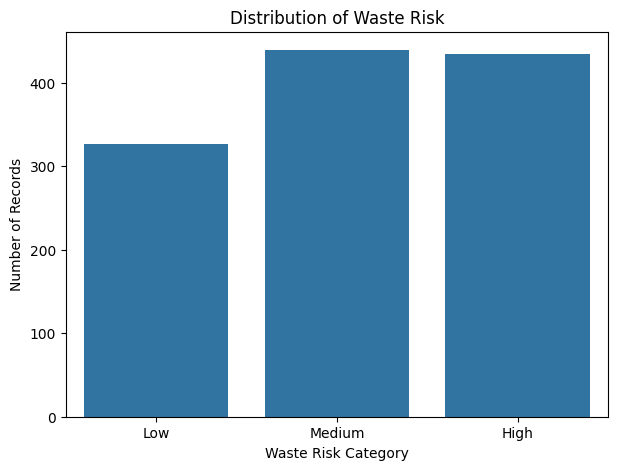

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="Waste_Risk",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Waste Risk")
plt.xlabel("Waste Risk Category")
plt.ylabel("Number of Records")

plt.show()

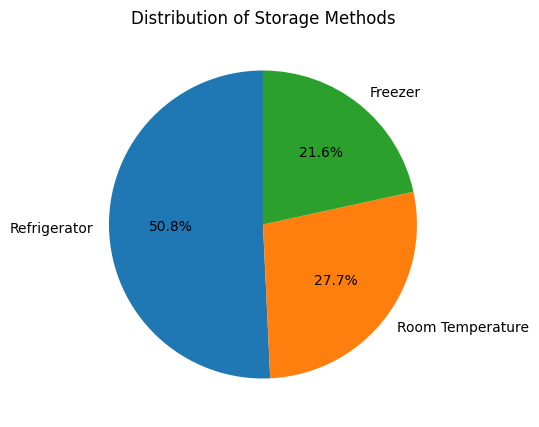

In [10]:
plt.figure(figsize=(7, 5))

data["Storage_Type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Storage Methods")
plt.ylabel("")

plt.show()

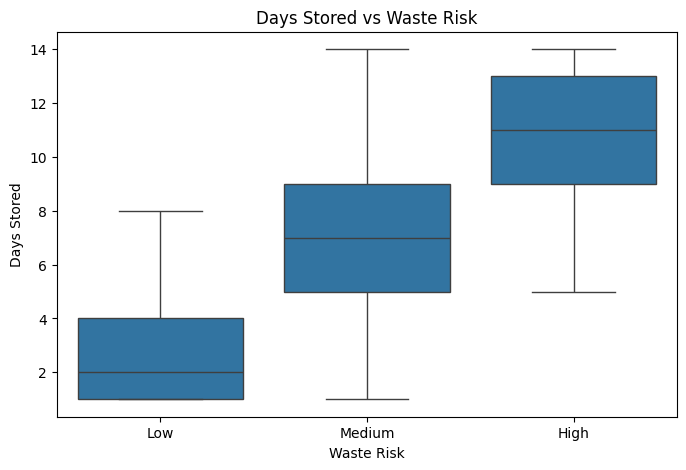

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Waste_Risk",
    y="Days_Stored",
    order=["Low", "Medium", "High"]
)

plt.title("Days Stored vs Waste Risk")

plt.xlabel("Waste Risk")
plt.ylabel("Days Stored")

plt.show()

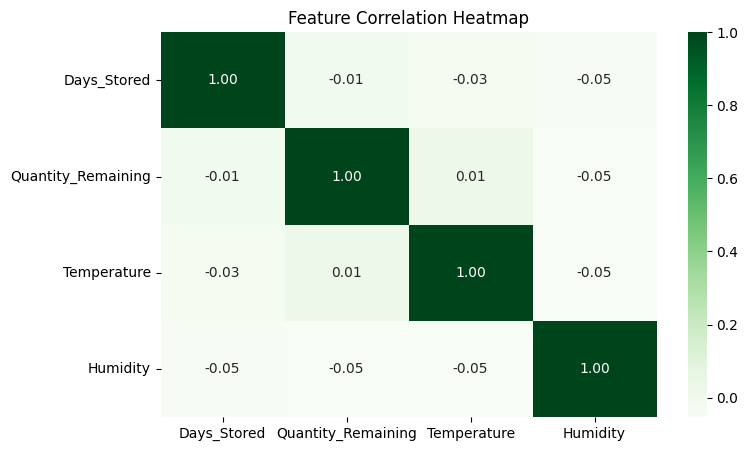

In [12]:
plt.figure(figsize=(8, 5))

numeric_data = data.select_dtypes(
    include=np.number
)

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="Greens",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [13]:
# Separating input and output variables

X = data.drop(
    columns=["Waste_Risk"]
)

y = data["Waste_Risk"]

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

Input Features:


,Food_Type,Storage_Type,Days_Stored,Quantity_Remaining,Temperature,Humidity
0,Milk,Refrigerator,7,65,7.0,68
1,Cooked Food,Room Temperature,9,64,29.7,36
2,Meat,Freezer,3,30,-13.0,86
3,Fruits,Room Temperature,9,82,27.4,41
4,Fruits,Freezer,13,72,-10.8,95



Target Variable:


,Waste_Risk
0,Medium
1,High
2,Low
3,High
4,High


In [14]:
# Identifying categorical and numerical features

categorical_features = [
    "Food_Type",
    "Storage_Type"
]

numerical_features = [
    "Days_Stored",
    "Quantity_Remaining",
    "Temperature",
    "Humidity"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Food_Type', 'Storage_Type']

Numerical Features:
['Days_Stored', 'Quantity_Remaining', 'Temperature', 'Humidity']


In [15]:
# Creating the preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),

        (
            "numerical",
            "passthrough",
            numerical_features
        )

    ]
)

print("Data preprocessing setup completed!")

Data preprocessing setup completed!


In [16]:
# Splitting dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

Dataset splitting completed!
Training Records: 960
Testing Records: 240


In [17]:
# Splitting dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset splitting completed!")

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

Dataset splitting completed!
Training Records: 960
Testing Records: 240


In [18]:
# Creating the Decision Tree model

model = Pipeline(
    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=7,
                random_state=42
            )
        )

    ]
)

# Training the model

model.fit(
    X_train,
    y_train
)

print("SmartPantry model trained successfully!")

SmartPantry model trained successfully!


In [19]:
# Predicting test data

y_pred = model.predict(X_test)

print("Predictions completed!")

print("\nFirst 10 Predictions:")

print(y_pred[:10])

Predictions completed!

First 10 Predictions:
['Medium' 'Medium' 'High' 'High' 'High' 'Low' 'High' 'Medium' 'Medium'
 'High']


In [20]:
# Calculating model accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Model Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

Model Accuracy: 87.92 %


In [21]:
# Classification report

print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.92      0.94        87
         Low       0.84      0.89      0.87        65
      Medium       0.84      0.83      0.83        88

    accuracy                           0.88       240
   macro avg       0.88      0.88      0.88       240
weighted avg       0.88      0.88      0.88       240



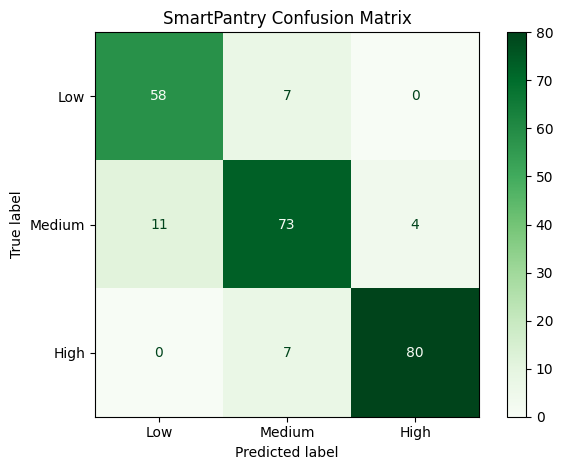

In [22]:
# Creating confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(
    cmap="Greens",
    values_format="d"
)

plt.title("SmartPantry Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
# Extracting feature importance

classifier = model.named_steps["classifier"]

feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = classifier.feature_importances_

feature_importance = pd.DataFrame({

    "Feature": feature_names,

    "Importance": importance

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")

display(feature_importance.head(10))

Feature Importance:


,Feature,Importance
10,numerical__Days_Stored,0.552984
12,numerical__Temperature,0.155811
0,categorical__Food_Type_Bread,0.058072
4,categorical__Food_Type_Meat,0.052959
2,categorical__Food_Type_Fruits,0.030513
13,numerical__Humidity,0.030224
1,categorical__Food_Type_Cooked Food,0.027927
7,categorical__Storage_Type_Freezer,0.023033
6,categorical__Food_Type_Vegetables,0.019548
9,categorical__Storage_Type_Room Temperature,0.017465


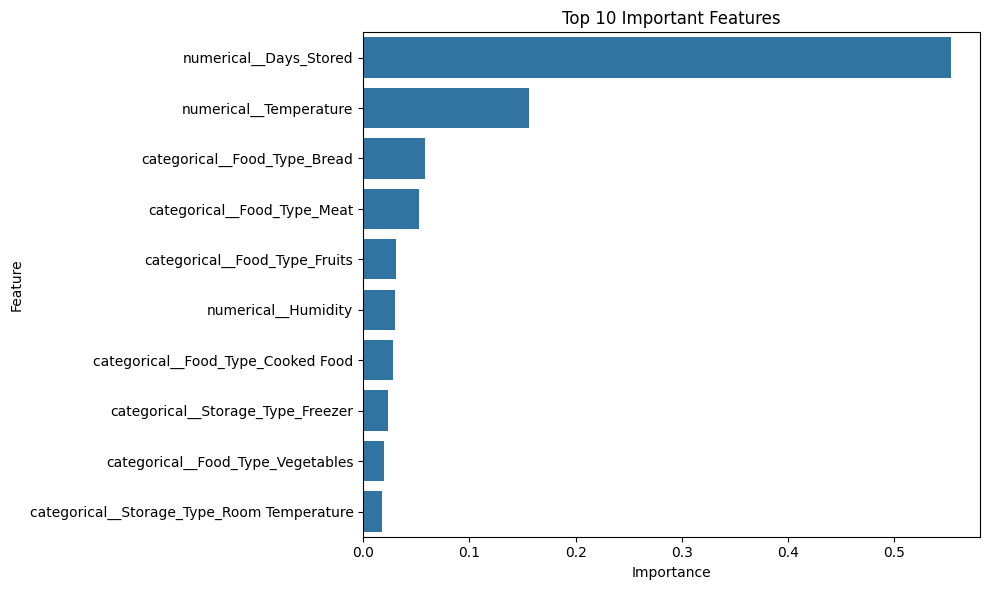

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [25]:
!pip -q install gradio

In [26]:
import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [27]:
# SmartPantry prediction function

def smartpantry_app(
    food_type,
    storage_type,
    days_stored,
    quantity_remaining,
    temperature,
    humidity
):

    # Creating a DataFrame from user inputs

    new_food = pd.DataFrame([{

        "Food_Type": food_type,

        "Storage_Type": storage_type,

        "Days_Stored": days_stored,

        "Quantity_Remaining": quantity_remaining,

        "Temperature": temperature,

        "Humidity": humidity

    }])

    # Predicting the risk category

    prediction = model.predict(new_food)[0]

    # Calculating model confidence

    probabilities = model.predict_proba(new_food)[0]

    confidence = max(probabilities) * 100

    # Creating recommendation

    if prediction == "High":

        icon = "🔴"

        recommendation = """
        **Prioritize checking this item.**

        Review its storage history, packaging and product label.
        Do not consume food that appears spoiled.
        """

    elif prediction == "Medium":

        icon = "🟡"

        recommendation = """
        **Consider checking this item soon.**

        Review its storage conditions and plan its use appropriately.
        """

    else:

        icon = "🟢"

        recommendation = """
        **The model estimates a lower waste risk.**

        Continue appropriate storage and regular checks.
        """

    # Formatting the output

    result = f"""
# {icon} SmartPantry Prediction

## Estimated Waste Risk: {prediction}

**Model confidence:** {confidence:.2f}%

---

### Food Details

| Parameter | Input |
|---|---|
| Food Type | {food_type} |
| Storage Method | {storage_type} |
| Days Stored | {days_stored} |
| Quantity Remaining | {quantity_remaining}% |
| Temperature | {temperature}°C |
| Humidity | {humidity}% |

---

### Recommendation

{recommendation}

---

*This is a simple ML model trained on sample data to estimate food waste risk, not actual food freshness or safety.*
"""

    return result

In [28]:
# SmartPantry custom interface

custom_css = """

.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
}

#main-header {
    background: linear-gradient(
        120deg,
        #123c32,
        #24745b
    );

    color: white;

    padding: 32px;

    border-radius: 18px;

    margin-bottom: 20px;

    text-align: center;
}

#main-header h1 {
    font-size: 38px;
    margin-bottom: 8px;
    color: white;
}

#main-header p {
    font-size: 15px;
    color: #e3f4eb;
}

#predict-button {
    background: #217653 !important;
    color: white !important;
    border-radius: 12px !important;
    font-weight: bold !important;
    min-height: 48px !important;
}

#result-panel {
    border: 1px solid #d5e9dc;
    border-radius: 15px;
    padding: 18px;
}

"""


# Creating the Gradio application

with gr.Blocks(

    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="emerald"
    ),

    css=custom_css,

    title="SmartPantry - Food Waste Predictor"

) as demo:


    # Application header

    gr.HTML("""
    <div id="main-header">

        <h1>🥬 SmartPantry</h1>

        <p>
        Smart Food Inventory & Waste Risk Prediction System
        </p>

        <p>
        Make informed food inventory decisions with Machine Learning.
        </p>

    </div>
    """)


    gr.Markdown(
        """
        ## Check Your Food Waste Risk

        Enter the food details below to receive an estimated risk category.
        """
    )


    with gr.Row():


        # Left column: User inputs

        with gr.Column(scale=1):

            gr.Markdown("### 🥗 Food Information")


            food_type = gr.Dropdown(

                choices=[
                    "Milk",
                    "Bread",
                    "Vegetables",
                    "Fruits",
                    "Meat",
                    "Cooked Food",
                    "Leafy Vegetables"
                ],

                value="Milk",

                label="Food Type"

            )


            storage_type = gr.Dropdown(

                choices=[
                    "Refrigerator",
                    "Room Temperature",
                    "Freezer"
                ],

                value="Refrigerator",

                label="Storage Method"

            )


            days_stored = gr.Slider(

                minimum=1,
                maximum=14,
                value=5,
                step=1,

                label="Days Stored"

            )


            quantity_remaining = gr.Slider(

                minimum=10,
                maximum=100,
                value=40,
                step=5,

                label="Quantity Remaining (%)"

            )


            gr.Markdown("### 🌡️ Storage Conditions")


            temperature = gr.Number(

                value=6,

                label="Temperature (°C)"

            )


            humidity = gr.Slider(

                minimum=35,
                maximum=95,
                value=70,
                step=1,

                label="Humidity (%)"

            )


            predict_button = gr.Button(

                "🔍 Predict Waste Risk",

                elem_id="predict-button"

            )



        # Right column: Prediction results

        with gr.Column(scale=1):

            gr.Markdown("### 📊 Prediction Results")


            result_output = gr.Markdown(

                value="""

                ## Welcome to SmartPantry!

                Enter your food details and click
                **Predict Waste Risk**.

                Your estimated risk category and recommendation
                will appear here.

                """,

                elem_id="result-panel"

            )


    gr.Markdown("---")


    gr.Markdown(
        """
        ### About SmartPantry

        SmartPantry is a machine learning prototype
        that classifies estimated food-waste risk into Low, Medium
        and High categories.

        **Technologies:** Python · Pandas · NumPy · Scikit-learn · Gradio
        """
    )


    # Connecting the prediction button

    predict_button.click(

        fn=smartpantry_app,

        inputs=[
            food_type,
            storage_type,
            days_stored,
            quantity_remaining,
            temperature,
            humidity
        ],

        outputs=result_output

    )


# Launching the application

demo.launch(share=True)

/tmp/ipykernel_897/460261612.py:58: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f591db43d45e258c3f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [29]:
import joblib

joblib.dump(model, "SmartPantry_Model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [30]:
from google.colab import files

files.download("SmartPantry_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>